# Rwanda Weather MLOps Pipeline: Weather Image Classification

**Author:** Oluwaloseyitowi Iji

## Overview
In my Introduction to Machine Learning summative I predicted next-day rainfall in Rwanda from tabular climate data. This project extends that use case to **images**: given a photo of the sky or surroundings, the model classifies the weather condition into one of five classes that matter for Rwanda:

| Class | Why it matters in Rwanda |
|---|---|
| `rain` | Main driver of floods and landslides in the rainy seasons |
| `fogsmog` | Reduces visibility on hilly roads, especially mornings in Kigali and the Northern Province |
| `lightning` | Rwanda has one of the highest lightning-strike rates in the world |
| `hail` | Damages crops and roofs during heavy storms |
| `rainbow` | Marks the end of rain (sun returning), a useful "storm has passed" signal |

**Dataset:** [Weather Image Recognition (Kaggle)](https://www.kaggle.com/datasets/jehanbhathena/weather-dataset), 6,862 images in 11 classes. I keep the 5 classes above.

## Pipeline in this notebook
1. Data acquisition
2. Feature extraction and EDA (3+ features interpreted)
3. Data processing (cleaning, resizing, splitting, augmentation, class weights)
4. Model creation (MobileNetV2 transfer learning)
5. Model training with optimisation (early stopping, learning-rate scheduling, dropout, L2, fine-tuning)
6. Model testing (loss, accuracy, precision, recall, F1, ROC-AUC, confusion matrix)
7. Prediction functions
8. Retraining check (load the saved model and fine-tune it on new data)
9. Saving the model and artefacts for the API

> Run this in Google Colab with a GPU: **Runtime → Change runtime type → T4 GPU**.

In [1]:
import sys, os, json, shutil, random
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__ if hasattr(tf.keras, "__version__") else "bundled")
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.13.9
TensorFlow: 2.21.0
Keras: 3.15.1
GPU: []


## 1. Data acquisition
The dataset is public, so `kagglehub` downloads it straight from Kaggle without manual steps. The code then finds the five class folders I need.

In [2]:
!pip -q install kagglehub
import kagglehub

raw_path = kagglehub.dataset_download("jehanbhathena/weather-dataset")
print("Downloaded to:", raw_path)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


100%|██████████| 587M/587M [00:43<00:00, 14.0MB/s] 

Extracting files...


Downloaded to: C:\Users\tenio\.cache\kagglehub\datasets\jehanbhathena\weather-dataset\versions\3


In [3]:
CLASSES = ["fogsmog", "hail", "lightning", "rain", "rainbow"]   # alphabetical = Keras label order
IMG_SIZE = 224

class_dirs = {}
for p in Path(raw_path).rglob("*"):
    if p.is_dir() and p.name in CLASSES and p.name not in class_dirs:
        class_dirs[p.name] = p

assert len(class_dirs) == len(CLASSES), f"Missing classes: {set(CLASSES) - set(class_dirs)}"
for c in CLASSES:
    print(f"{c:10s} {len(list(class_dirs[c].iterdir()))} files")

fogsmog    851 files
hail       591 files
lightning  377 files
rain       526 files
rainbow    232 files


## 2. Feature extraction
Images do not come with columns, so I extract simple, interpretable features from every raw image before resizing:

- **width / height**: original resolution
- **brightness**: mean grey-level intensity (0 to 255)
- **contrast**: standard deviation of grey-level intensity
- **r, g, b**: mean value of each colour channel
- **saturation**: mean colour saturation (HSV)

This step also acts as a **data-quality check**: any file that cannot be opened is reported and excluded.

In [4]:
from PIL import Image, ImageOps

records, bad = [], []
for c in CLASSES:
    for f in sorted(class_dirs[c].iterdir()):
        try:
            with Image.open(f) as im:
                im = ImageOps.exif_transpose(im)
                w, h = im.size
                rgb = im.convert("RGB").resize((128, 128))
                arr = np.asarray(rgb, dtype=np.float32)
                gray = np.asarray(rgb.convert("L"), dtype=np.float32)
                hsv = np.asarray(rgb.convert("HSV"), dtype=np.float32)
            records.append({
                "path": str(f), "label": c, "width": w, "height": h,
                "brightness": gray.mean(), "contrast": gray.std(),
                "r": arr[..., 0].mean(), "g": arr[..., 1].mean(), "b": arr[..., 2].mean(),
                "saturation": hsv[..., 1].mean(),
            })
        except Exception as e:
            bad.append((str(f), str(e)))

df = pd.DataFrame(records)
print(f"{len(df)} valid images, {len(bad)} unreadable (excluded)")
df.groupby("label").size().rename("images").to_frame()

2577 valid images, 0 unreadable (excluded)


,images
label,
fogsmog,851
hail,591
lightning,377
rain,526
rainbow,232


## 3. Data processing

### 3.1 Splitting
- **20 images per class** are held back in `data/retrain_demo/`. The model never sees them, so I can upload them through the app later to demonstrate retraining on genuinely new data.
- The rest is split **80% train / 20% test**, stratified so every class keeps the same proportion in both sets.
- During training, 15% of the training set is used for **validation** (this drives early stopping), so the test set stays untouched until final evaluation.

### 3.2 Resizing
Every image is converted to RGB, EXIF-rotated, resized to **224×224** (MobileNetV2's native input size) and saved as JPEG. This standardises the inputs and also shrinks the dataset enough to live in the GitHub repo.

In [5]:
from sklearn.model_selection import train_test_split

RETRAIN_PER_CLASS = 20
retrain_df = df.groupby("label").sample(n=RETRAIN_PER_CLASS, random_state=SEED)
rest = df.drop(retrain_df.index)
train_df, test_df = train_test_split(rest, test_size=0.2, stratify=rest["label"], random_state=SEED)

split_counts = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
    "retrain_demo": retrain_df["label"].value_counts(),
}).loc[CLASSES]
split_counts.loc["TOTAL"] = split_counts.sum()
split_counts

,train,test,retrain_demo
label,,,
fogsmog,665,166,20
hail,457,114,20
lightning,285,72,20
rain,405,101,20
rainbow,169,43,20
TOTAL,1981,496,100


In [6]:
OUT = Path("project")          # mirrors the repo root: project/data, project/models
DATA = OUT / "data"
MODELS = OUT / "models"
if OUT.exists():
    shutil.rmtree(OUT)

def resize_and_save(src, dst, size=IMG_SIZE):
    with Image.open(src) as im:
        im = ImageOps.exif_transpose(im).convert("RGB").resize((size, size), Image.BILINEAR)
    dst.parent.mkdir(parents=True, exist_ok=True)
    im.save(dst, "JPEG", quality=90)

for split, part in [("train", train_df), ("test", test_df), ("retrain_demo", retrain_df)]:
    for row in part.itertuples():
        resize_and_save(row.path, DATA / split / row.label / f"{Path(row.path).stem}.jpg")

size_mb = sum(f.stat().st_size for f in DATA.rglob("*.jpg")) / 1e6
print(f"Saved processed images: {size_mb:.1f} MB")

Saved processed images: 31.5 MB


## 4. Exploratory data analysis and feature interpretation  

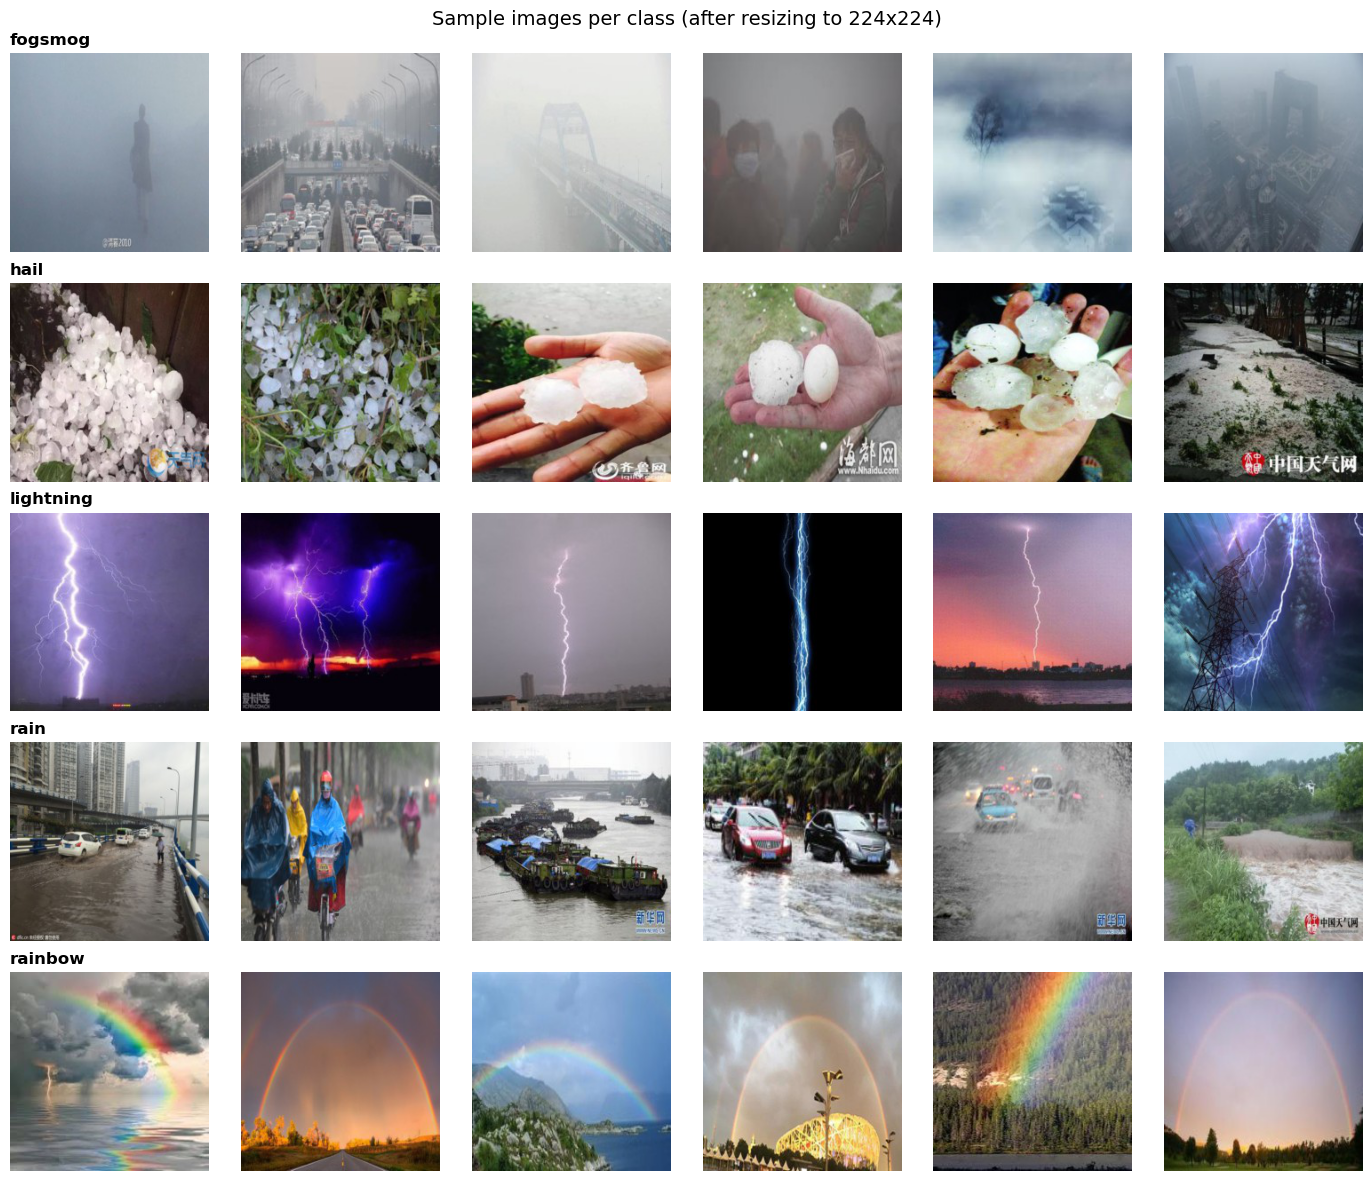

In [7]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(14, 12))
for i, c in enumerate(CLASSES):
    files = sorted((DATA / "train" / c).glob("*.jpg"))
    for j, f in enumerate(random.sample(files, 6)):
        axes[i, j].imshow(Image.open(f)); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Sample images per class (after resizing to 224x224)", fontsize=14)
plt.tight_layout(); plt.show()

### Feature 1: Class distribution

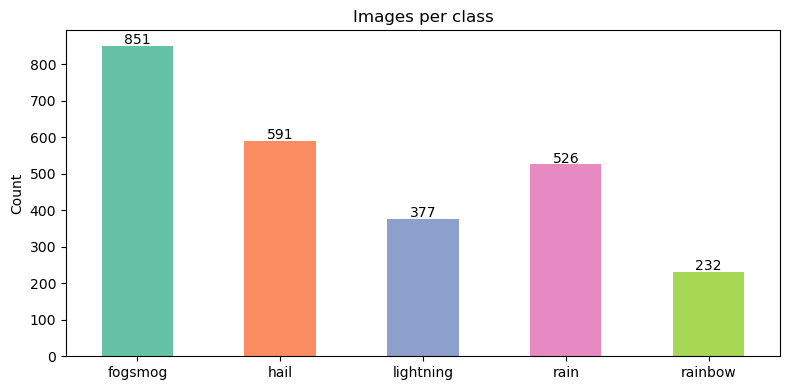

Imbalance ratio (largest / smallest): 3.67


In [8]:
counts = df["label"].value_counts().loc[CLASSES]
ax = counts.plot(kind="bar", color=sns.color_palette("Set2", len(CLASSES)), figsize=(8, 4))
ax.set_title("Images per class"); ax.set_ylabel("Count"); ax.set_xlabel("")
for i, v in enumerate(counts): ax.text(i, v + 5, str(v), ha="center")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Imbalance ratio (largest / smallest):", round(counts.max() / counts.min(), 2))

**Interpretation.** The classes are **not balanced**: fog/smog has the most images and rainbow the fewest. A model trained on this as-is would lean towards the common classes, and accuracy alone would hide poor performance on rare ones. This finding drives two decisions:
1. I use **class weights** during training so mistakes on rare classes cost more.
2. I report **precision, recall and F1 per class**, not just accuracy.

### Feature 2: Brightness and contrast

C:\Users\tenio\AppData\Local\Temp\ipykernel_24896\1948964358.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y="brightness", order=CLASSES, palette="Set2", ax=axes[0])
C:\Users\tenio\AppData\Local\Temp\ipykernel_24896\1948964358.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y="contrast", order=CLASSES, palette="Set2", ax=axes[1])


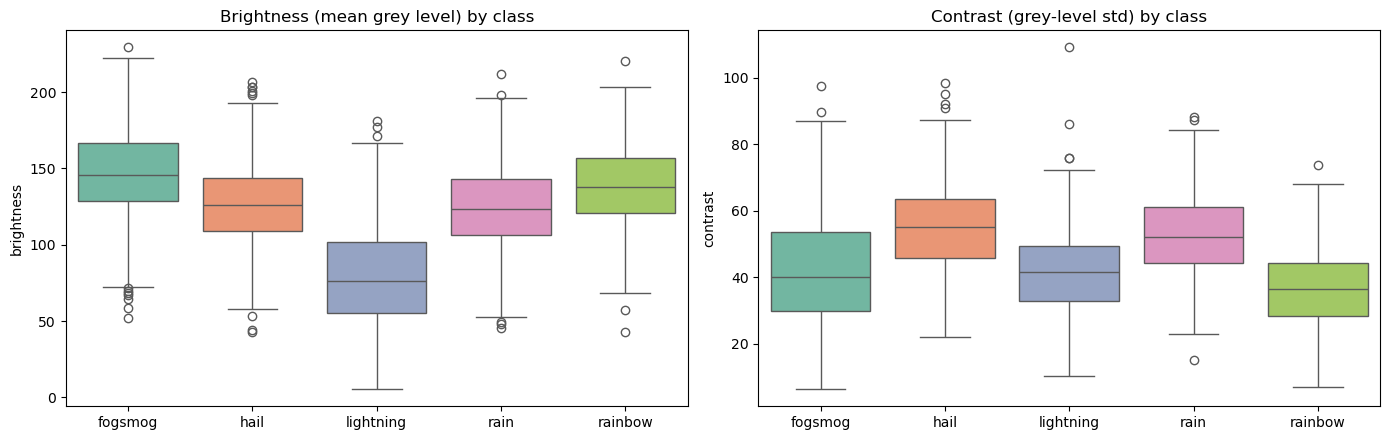

,brightness,contrast
label,,
fogsmog,145.899994,40.099998
hail,125.900002,55.099998
lightning,76.400002,41.700001
rain,123.400002,52.299999
rainbow,138.199997,36.599998


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="label", y="brightness", order=CLASSES, palette="Set2", ax=axes[0])
axes[0].set_title("Brightness (mean grey level) by class"); axes[0].set_xlabel("")
sns.boxplot(data=df, x="label", y="contrast", order=CLASSES, palette="Set2", ax=axes[1])
axes[1].set_title("Contrast (grey-level std) by class"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
df.groupby("label")[["brightness", "contrast"]].median().loc[CLASSES].round(1)

**Interpretation.** **Lightning** images are by far the darkest, because lightning is mostly photographed at night against a black sky. They also have high contrast (a bright bolt against darkness). **Fog/smog** sits at the other extreme: fairly bright but with the **lowest contrast**, because fog washes out edges and flattens everything into similar greys. Brightness and contrast alone already separate these two classes well, which tells us the CNN has strong low-level signals to learn from. Rain and hail overlap heavily on both features, so I expect most confusion between those two.

### Feature 3: Colour profile (RGB channels and saturation)

C:\Users\tenio\AppData\Local\Temp\ipykernel_24896\1325867745.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y="saturation", order=CLASSES, palette="Set2", ax=axes[1])


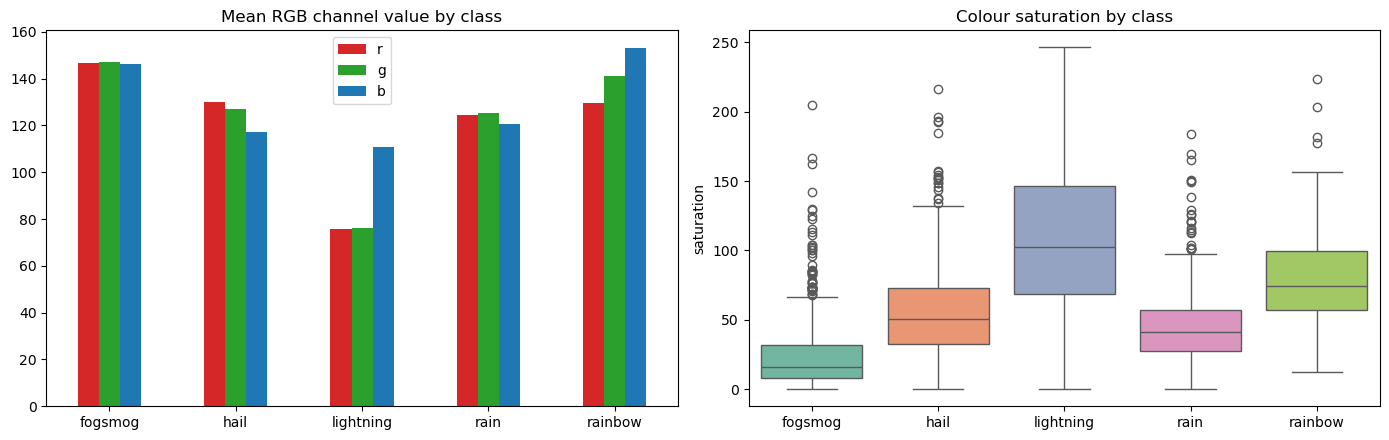

,r,g,b,saturation
label,,,,
fogsmog,146.699997,147.199997,146.300003,24.100000
hail,130.000000,127.099998,117.300003,55.799999
lightning,75.900002,76.000000,110.900002,110.800003
rain,124.400002,125.199997,120.599998,46.099998
rainbow,129.500000,140.899994,153.000000,79.300003


In [10]:
colour = df.groupby("label")[["r", "g", "b", "saturation"]].mean().loc[CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colour[["r", "g", "b"]].plot(kind="bar", color=["#d62728", "#2ca02c", "#1f77b4"], ax=axes[0])
axes[0].set_title("Mean RGB channel value by class"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
sns.boxplot(data=df, x="label", y="saturation", order=CLASSES, palette="Set2", ax=axes[1])
axes[1].set_title("Colour saturation by class"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
colour.round(1)

**Interpretation.** **Fog/smog** has the lowest saturation (24) and almost identical R, G and B means (about 147 each), which is exactly what grey looks like numerically. **Lightning** has the highest saturation (111) and a strong **blue/purple cast**: its blue channel (111) sits far above red and green (about 76), from the purple glow of lightning against night skies. **Rainbow** images are the bluest overall (153) because they are shot against open sky, and have the second-highest saturation (79). Rain and hail again look alike, with neutral colours and low-to-medium saturation. Since colour carries this much signal, I **do not** use hue or colour-shift augmentation: it could make a fog image look like lightning, or wash out a rainbow.

### Feature 4: Original image resolution

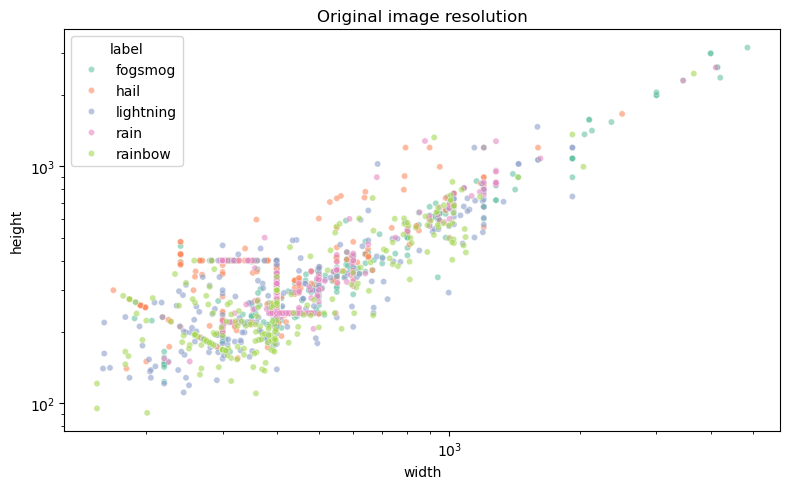

,width,height
count,2577.0,2577.0
mean,481.0,336.0
std,345.0,232.0
min,154.0,91.0
25%,387.0,240.0
50%,400.0,267.0
75%,427.0,346.0
max,4863.0,3174.0


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="width", y="height", hue="label", hue_order=CLASSES, palette="Set2", alpha=0.6, s=20, ax=ax)
ax.set_title("Original image resolution"); ax.set_xscale("log"); ax.set_yscale("log")
plt.tight_layout(); plt.show()
df[["width", "height"]].describe().round(0)

**Interpretation.** Raw images vary from tiny thumbnails to multi-megapixel photos with very different aspect ratios, because they were collected from many web sources. A model needs a fixed input shape, so resizing every image to 224×224 is a required step, not an optional one. This also explains why I built the resizing into both the notebook and the API (`src/preprocessing.py`): any image a user uploads, at any size, goes through the same transformation.

In [12]:
# Save feature summaries for the dashboard's Insights page
MODELS.mkdir(parents=True, exist_ok=True)
insights = {
    "class_counts": {c: int(v) for c, v in counts.items()},
    "split_counts": {s: {c: int(split_counts.loc[c, s]) for c in CLASSES} for s in ["train", "test", "retrain_demo"]},
    "brightness_median": df.groupby("label")["brightness"].median().loc[CLASSES].round(1).to_dict(),
    "contrast_median": df.groupby("label")["contrast"].median().loc[CLASSES].round(1).to_dict(),
    "saturation_median": df.groupby("label")["saturation"].median().loc[CLASSES].round(1).to_dict(),
    "rgb_mean": {c: colour.loc[c, ["r", "g", "b"]].round(1).tolist() for c in CLASSES},
}
with open(MODELS / "insights.json", "w") as f:
    json.dump(insights, f, indent=2)
print("Saved models/insights.json")

Saved models/insights.json


### 4.1 Building the input pipeline
- `image_dataset_from_directory` reads the processed folders and labels images by folder name.
- **Data augmentation** (training only): horizontal flip, small rotation, zoom and contrast changes. These mimic real variation in how people take photos. I avoid **vertical flips** (the sky is always up) and **colour shifts** (colour is a key feature, see Feature 3).
- **Normalisation** to the [-1, 1] range MobileNetV2 expects is done by a `Rescaling` layer **inside the model**. This means the API can feed raw 0 to 255 pixels and preprocessing can never drift between training and production.
- **Class weights** counter the imbalance found in Feature 1.

In [13]:
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

common = dict(image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH, label_mode="int", class_names=CLASSES)
train_ds = tf.keras.utils.image_dataset_from_directory(str(DATA / "train"), validation_split=0.15,
                                                       subset="training", seed=SEED, **common)
val_ds = tf.keras.utils.image_dataset_from_directory(str(DATA / "train"), validation_split=0.15,
                                                     subset="validation", seed=SEED, **common)
test_ds = tf.keras.utils.image_dataset_from_directory(str(DATA / "test"), shuffle=False, **common)

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.2),
], name="augment")

train_ds = train_ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

from sklearn.utils.class_weight import compute_class_weight
y_train = train_df["label"].map(CLASSES.index).values
class_weight = dict(enumerate(compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)))
print("Class weights:", {CLASSES[k]: round(v, 2) for k, v in class_weight.items()})

Found 1981 files belonging to 5 classes.
Using 1684 files for training.
Found 1981 files belonging to 5 classes.
Using 297 files for validation.
Found 496 files belonging to 5 classes.
Class weights: {'fogsmog': np.float64(0.6), 'hail': np.float64(0.87), 'lightning': np.float64(1.39), 'rain': np.float64(0.98), 'rainbow': np.float64(2.34)}


Found 1981 files belonging to 5 classes.


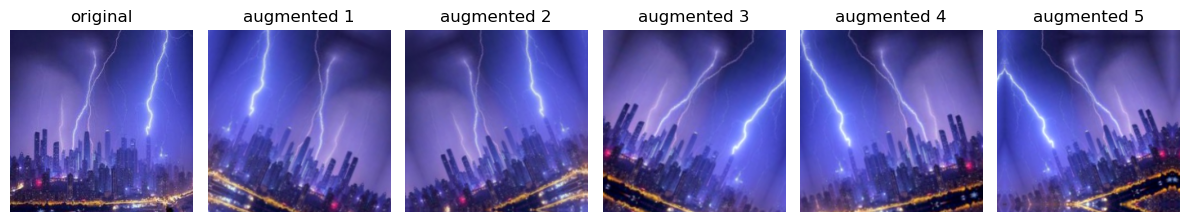

In [14]:
# What augmentation does to one image
sample_img = next(iter(tf.keras.utils.image_dataset_from_directory(str(DATA / "train"), **{**common, "batch_size": 1})))[0]
plt.figure(figsize=(12, 3))
for i in range(6):
    ax = plt.subplot(1, 6, i + 1)
    img = sample_img if i == 0 else augment(sample_img, training=True)
    plt.imshow(tf.cast(img[0], tf.uint8)); plt.axis("off"); plt.title("original" if i == 0 else f"augmented {i}")
plt.tight_layout(); plt.show()

## 5. Model creation
**Transfer learning with MobileNetV2** (pretrained on ImageNet's 1.2M images):
- The pretrained base already knows edges, textures and colours, so it needs far less data than training from scratch. That suits our ~2,500-image dataset.
- It is small (~9 MB) and fast on CPU, which matters for a free cloud server and for the Locust load test.

**Custom head with regularisation:** GlobalAveragePooling → Dropout(0.3) → Dense(128, ReLU, **L2 1e-4**) → Dropout(0.3) → Softmax(5). Dropout and L2 both fight overfitting.

In [15]:
from tensorflow.keras import layers, regularizers

def build_model(num_classes=len(CLASSES), dropout=0.3, l2=1e-4):
    base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                             include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = layers.Rescaling(1.0 / 127.5, offset=-1, name="normalise")(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return tf.keras.Model(inputs, outputs, name="weather_mobilenetv2"), base

model, base = build_model()
model.summary()

Model: "weather_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalise (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Training with optimisation

**Phase 1: train the head only** (base frozen), Adam at learning rate 1e-3.

**Phase 2: fine-tune** the top 30 layers of MobileNetV2 at a much lower learning rate (1e-5), so the pretrained features adapt to weather images without being destroyed.

**Callbacks:**
- **EarlyStopping** (monitor `val_loss`, patience 4, restore best weights): training stops once the model stops improving on data it has not trained on. Without it, the model keeps fitting the training images (training loss keeps falling) while validation loss starts rising, which is overfitting. Restoring the best weights means we keep the model from its best epoch, not its last one.
- **ReduceLROnPlateau**: if validation loss stalls, the learning rate is cut by 70% so the optimiser can take smaller, more careful steps.

In [16]:
def callbacks(patience=4):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=20,
                  class_weight=class_weight, callbacks=callbacks())

Epoch 1/20


c:\Users\tenio\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 661ms/step - accuracy: 0.7672 - loss: 0.6232 - val_accuracy: 0.9226 - val_loss: 0.2167 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 30s 551ms/step - accuracy: 0.9240 - loss: 0.2425 - val_accuracy: 0.9495 - val_loss: 0.1895 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 29s 526ms/step - accuracy: 0.9371 - loss: 0.1845 - val_accuracy: 0.9529 - val_loss: 0.1689 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 30s 541ms/step - accuracy: 0.9460 - loss: 0.1722 - val_accuracy: 0.9529 - val_loss: 0.1694 - learning_rate: 0.0010
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 31s 567ms/step - accuracy: 0.9513 - loss: 0.1603 - val_accuracy: 0.9663 - val_loss: 0.1551 - learning_rate: 0.0010
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 33s 598ms/step - accuracy: 0.9578 - loss: 0.1329 - val_accuracy: 0.9630 - val_loss: 0.1422 - learning_rate: 0.0010
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 605s 12s/step - accuracy: 0.9632 - loss: 0.1087 - val_a

## 7. Model testing
The evaluation function computes **6 metrics** on the held-out test set:
- **Loss** (cross-entropy): how confident and correct the probabilities are
- **Accuracy**: share of images classified correctly
- **Precision** (macro): when the model says "hail", how often is it really hail?
- **Recall** (macro): of all real hail images, how many did the model catch?
- **F1** (macro and weighted): balance of precision and recall. Macro treats every class equally, so it is honest about rare classes.
- **ROC-AUC** (one-vs-rest): how well the model ranks the right class above the others, independent of a threshold

In [17]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix)

def evaluate(m, ds):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    probs = m.predict(ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    metrics = {
        "loss": float(tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(y_true, probs))),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro"),
        "recall_macro": recall_score(y_true, y_pred, average="macro"),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
        "roc_auc_ovr": roc_auc_score(y_true, probs, multi_class="ovr"),
    }
    return {k: round(float(v), 4) for k, v in metrics.items()}, y_true, y_pred, probs

metrics_frozen, *_ = evaluate(model, test_ds)
metrics_frozen

{'loss': 0.0967,
 'accuracy': 0.9718,
 'precision_macro': 0.9697,
 'recall_macro': 0.9711,
 'f1_macro': 0.9702,
 'f1_weighted': 0.9718,
 'roc_auc_ovr': 0.9987}

In [18]:
# Phase 2: fine-tuning
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False      # keep pretrained batch statistics stable

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
start = len(hist1.history["loss"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=start + 15, initial_epoch=start,
                  class_weight=class_weight, callbacks=callbacks())

Epoch 12/26


c:\Users\tenio\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


53/53 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.9662 - loss: 0.1140 - val_accuracy: 0.9562 - val_loss: 0.1447 - learning_rate: 1.0000e-05
Epoch 13/26
53/53 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.9703 - loss: 0.0969 - val_accuracy: 0.9697 - val_loss: 0.1311 - learning_rate: 1.0000e-05
Epoch 14/26
53/53 ━━━━━━━━━━━━━━━━━━━━ 51s 927ms/step - accuracy: 0.9786 - loss: 0.0864 - val_accuracy: 0.9663 - val_loss: 0.1251 - learning_rate: 1.0000e-05
Epoch 15/26
53/53 ━━━━━━━━━━━━━━━━━━━━ 43s 783ms/step - accuracy: 0.9715 - loss: 0.0881 - val_accuracy: 0.9697 - val_loss: 0.1137 - learning_rate: 1.0000e-05
Epoch 16/26
53/53 ━━━━━━━━━━━━━━━━━━━━ 45s 809ms/step - accuracy: 0.9762 - loss: 0.0742 - val_accuracy: 0.9731 - val_loss: 0.1096 - learning_rate: 1.0000e-05
Epoch 17/26
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 735ms/step - accuracy: 0.9893 - loss: 0.0561 - val_accuracy: 0.9663 - val_loss: 0.1204 - learning_rate: 1.0000e-05
Epoch 18/26
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - accuracy: 0.978

In [19]:
metrics_final, y_true, y_pred, probs = evaluate(model, test_ds)

comparison = pd.DataFrame({"Phase 1: frozen base": metrics_frozen,
                           "Phase 2: fine-tuned (final)": metrics_final})
comparison

,Phase 1: frozen base,Phase 2: fine-tuned (final)
loss,0.0967,0.0934
accuracy,0.9718,0.9758
precision_macro,0.9697,0.9795
recall_macro,0.9711,0.9743
f1_macro,0.9702,0.9768
f1_weighted,0.9718,0.9758
roc_auc_ovr,0.9987,0.9987


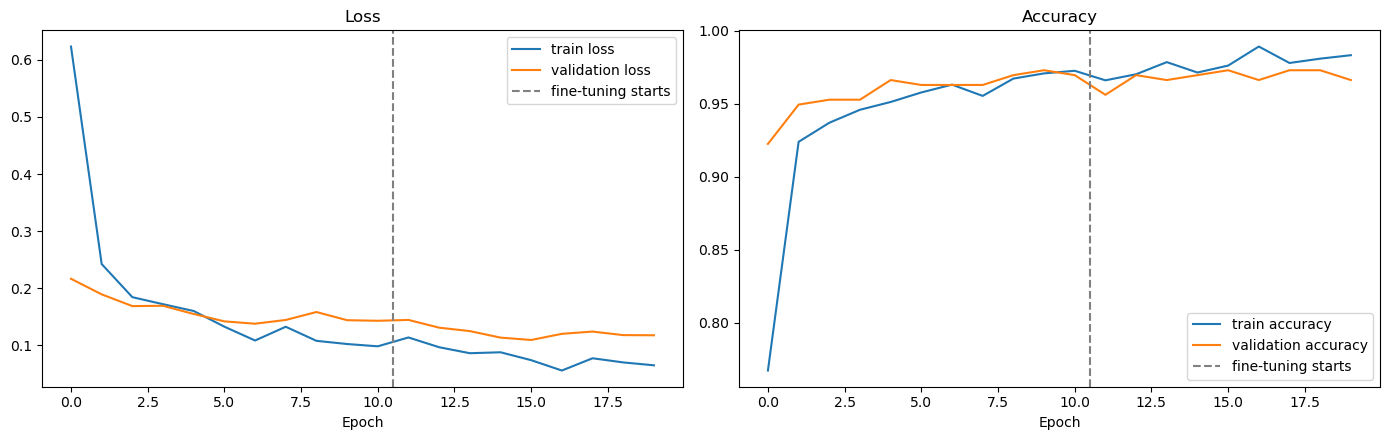

In [20]:
# Learning curves across both phases
h = {k: hist1.history[k] + hist2.history[k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, key in zip(axes, ["loss", "accuracy"]):
    ax.plot(h[key], label=f"train {key}"); ax.plot(h[f"val_{key}"], label=f"validation {key}")
    ax.axvline(start - 0.5, color="grey", ls="--", label="fine-tuning starts")
    ax.set_title(key.capitalize()); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

     fogsmog      0.959     0.982     0.970       166
        hail      0.983     1.000     0.991       114
   lightning      1.000     0.972     0.986        72
        rain      0.979     0.941     0.960       101
     rainbow      0.977     0.977     0.977        43

    accuracy                          0.976       496
   macro avg      0.980     0.974     0.977       496
weighted avg      0.976     0.976     0.976       496



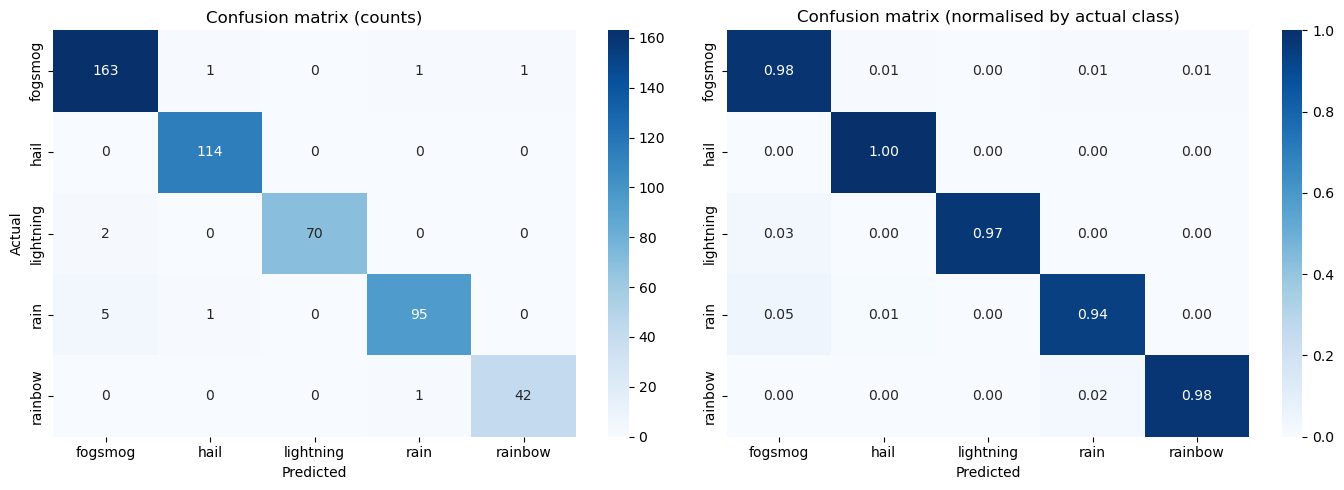

In [21]:
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Confusion matrix (normalised by actual class)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

### Interpreting the results
- **Why fine-tuning helped:** the comparison table shows the fine-tuned model beats the frozen one. ImageNet features are general (dogs, cars, cups). Unfreezing the top layers lets them specialise in weather textures like rain streaks and hail pellets.
- **Why macro F1 is the headline metric:** the classes are imbalanced (Feature 1). Macro F1 gives rainbow, the smallest class, the same weight as fog, so a high macro F1 means the model is good across *all* classes, not just the common ones.
- **Where it struggles:** check the confusion matrix. Most errors should fall between **rain and hail**, which matches the EDA: both are wet, grey scenes with similar brightness and contrast (Feature 2). Lightning and rainbow should be the easiest, because their brightness and colour profiles are so distinctive (Features 2 and 3).
- **Overfitting check:** in the learning curves, training and validation curves stay close together, and early stopping ended each phase once validation loss stopped improving.

## 8. Prediction functions
`predict_image` takes a file path and returns the predicted class, its confidence and the full probability distribution. The same logic is used by the API in `src/prediction.py`.

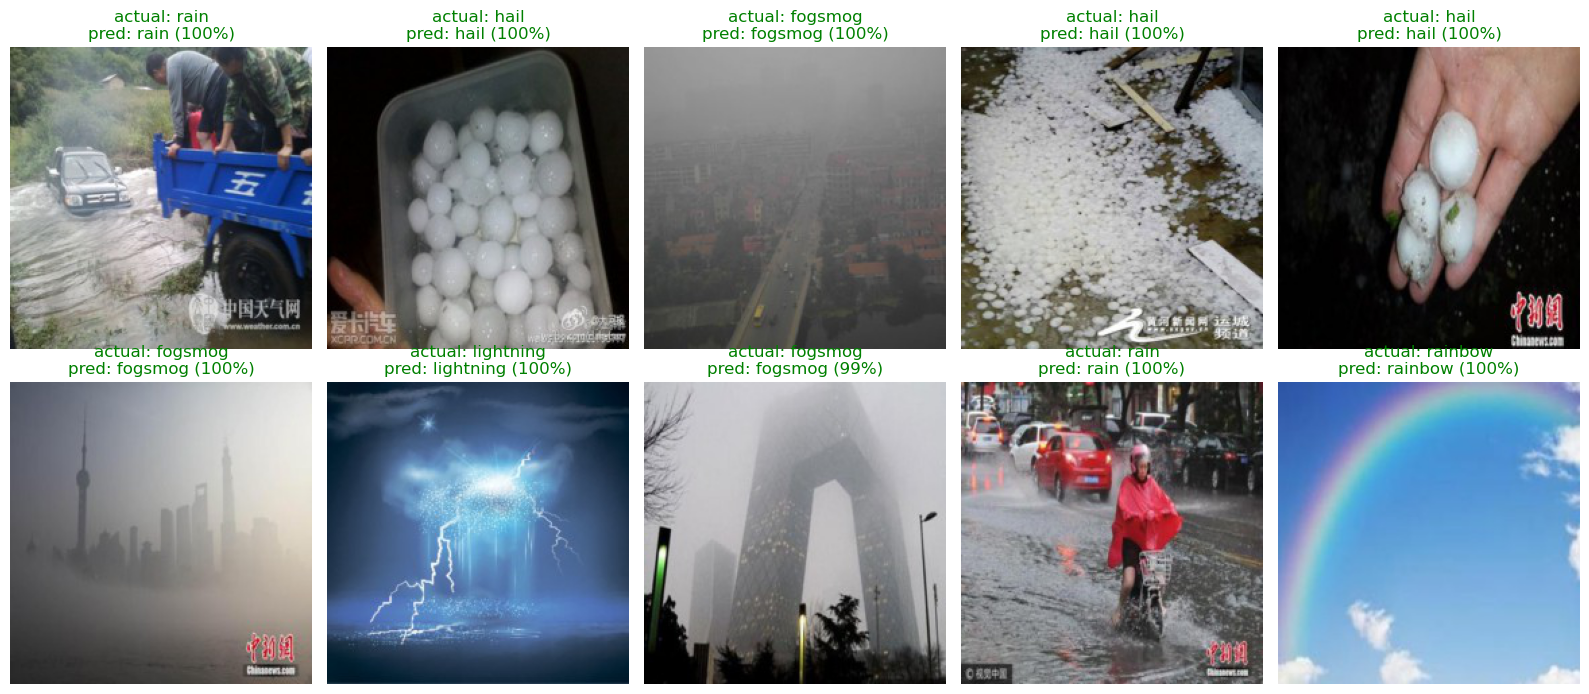

('rain', 0.9992444515228271, {'fogsmog': 0.0, 'hail': 0.0008, 'lightning': 0.0, 'rain': 0.9992, 'rainbow': 0.0})


In [22]:
def load_for_prediction(path):
    img = tf.keras.utils.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
    return tf.keras.utils.img_to_array(img)[None, ...]        # raw 0-255, model normalises internally

def predict_image(m, path):
    probs = m.predict(load_for_prediction(path), verbose=0)[0]
    idx = int(probs.argmax())
    return CLASSES[idx], float(probs[idx]), {c: round(float(p), 4) for c, p in zip(CLASSES, probs)}

test_files = sorted((DATA / "test").rglob("*.jpg"))
picks = random.sample(test_files, 10)
plt.figure(figsize=(16, 7))
for i, f in enumerate(picks):
    label, conf, _ = predict_image(model, f)
    actual = f.parent.name
    plt.subplot(2, 5, i + 1); plt.imshow(Image.open(f)); plt.axis("off")
    plt.title(f"actual: {actual}\npred: {label} ({conf:.0%})", color="green" if label == actual else "red")
plt.tight_layout(); plt.show()

print(predict_image(model, picks[0]))

## 9. Save the model and artefacts
- `weather_model.h5`: the trained model (normalisation layer included)
- `class_names.json`: label order the API uses to decode predictions
- `metrics.json`: final test metrics, shown on the dashboard and used as the baseline when deciding whether a retrained model should replace this one
- `insights.json`: feature summaries for the dashboard (saved in section 4)

In [23]:
MODEL_PATH = MODELS / "weather_model.h5"
model.save(MODEL_PATH)

with open(MODELS / "class_names.json", "w") as f:
    json.dump(CLASSES, f)

report = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True)
with open(MODELS / "metrics.json", "w") as f:
    json.dump({
        "model_version": 1,
        "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "tensorflow_version": tf.__version__,
        "test_metrics": metrics_final,
        "phase_comparison": {"frozen": metrics_frozen, "fine_tuned": metrics_final},
        "per_class": {c: {k: round(report[c][k], 4) for k in ["precision", "recall", "f1-score", "support"]} for c in CLASSES},
        "confusion_matrix": cm.tolist(),
        "n_train_images": int(len(train_df)),
    }, f, indent=2)

print(f"Model saved: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

Model saved: project\models\weather_model.h5 (23.5 MB)


## 10. Retraining check
This proves the saved `.h5` file can be **reloaded and used as the pretrained starting point** for retraining, which is exactly what the API's retrain button does:
1. Load the saved model
2. Combine the existing training data with the new `retrain_demo` images
3. Fine-tune with a low learning rate and early stopping
4. Compare against the current model and only keep the new one if it is at least as good

The result is **not** saved here. The real retraining happens through the app.

In [24]:
reloaded = tf.keras.models.load_model(MODEL_PATH)
reloaded_metrics, *_ = evaluate(reloaded, test_ds)
print("Reloaded model matches saved model:", reloaded_metrics["accuracy"] == metrics_final["accuracy"])

new_ds = tf.keras.utils.image_dataset_from_directory(str(DATA / "retrain_demo"), shuffle=True, seed=SEED, **common)
old_ds = tf.keras.utils.image_dataset_from_directory(str(DATA / "train"), shuffle=True, seed=SEED, **common)
combined = old_ds.concatenate(new_ds).shuffle(64, seed=SEED) \
                 .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

reloaded.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
reloaded.fit(combined, validation_data=val_ds, epochs=3, class_weight=class_weight, callbacks=callbacks(patience=2))

retrained_metrics, *_ = evaluate(reloaded, test_ds)
pd.DataFrame({"current model": metrics_final, "retrained model": retrained_metrics})

Reloaded model matches saved model: True
Found 100 files belonging to 5 classes.
Found 1981 files belonging to 5 classes.
Epoch 1/3


c:\Users\tenio\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 ━━━━━━━━━━━━━━━━━━━━ 56s 711ms/step - accuracy: 0.9741 - loss: 0.0864 - val_accuracy: 0.9764 - val_loss: 0.1039 - learning_rate: 1.0000e-05
Epoch 2/3
66/66 ━━━━━━━━━━━━━━━━━━━━ 44s 645ms/step - accuracy: 0.9793 - loss: 0.0770 - val_accuracy: 0.9798 - val_loss: 0.0927 - learning_rate: 1.0000e-05
Epoch 3/3
66/66 ━━━━━━━━━━━━━━━━━━━━ 87s 738ms/step - accuracy: 0.9808 - loss: 0.0745 - val_accuracy: 0.9832 - val_loss: 0.0835 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 3.


,current model,retrained model
loss,0.0934,0.0797
accuracy,0.9758,0.9798
precision_macro,0.9795,0.9816
recall_macro,0.9743,0.9798
f1_macro,0.9768,0.9807
f1_weighted,0.9758,0.9798
roc_auc_ovr,0.9987,0.9990


## 11. Download the outputs
This zips `data/` and `models/` so they can be extracted straight into the repo root.

In [25]:
shutil.make_archive("rwanda_weather_outputs", "zip", OUT)
print(f"Zip size: {Path('rwanda_weather_outputs.zip').stat().st_size / 1e6:.1f} MB")
try:
    from google.colab import files
    files.download("rwanda_weather_outputs.zip")
except ImportError:
    print("Not in Colab: zip saved next to the notebook.")

Zip size: 52.9 MB
Not in Colab: zip saved next to the notebook.
